# HW1. Задача 1: реакция пользователя

Нужно по диалогу определить реакцию пользователя: `negative`, `neutral` или `positive`. Ноутбук собран из того, что мы прошли на семинарах: Naive Bayes (занятие 1), логистическая регрессия и SVM (3), метрики, кросс-валидация, подбор гиперпараметров, тексты и TF-IDF, сохранение конвейера (4), SVD и ядра (5).

План:
1. данные и разведочный анализ
2. чистка и обработка текста
3. разбиение и метрики
4. baseline
5. три базовые модели и вложенная кросс-валидация
6. своя модель
7. своя гипотеза: какая часть диалога несёт реакцию
8. итоговая оценка на тестовом сете
9. разбор ошибок
10. сохранение моделей

## 0. Подготовка

In [ ]:
import os, platform, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn
from IPython.display import display

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.pipeline import Pipeline

import solution_utils as su

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 110, "display.width", 200)
SEED = 42
DATA = os.environ.get("HW1_TRAIN", "../hw1_train.jsonl")
os.makedirs(su.ARTIFACTS, exist_ok=True)

In [ ]:
def show_table(frame, digits=3, axis=0):
    """Таблица с заливкой: большие значения ярче.

    axis=0 — каждый столбец со своей шкалой, axis=None — одна шкала на всю таблицу.
    """
    numeric = frame.select_dtypes("number").columns
    styled = frame.style.background_gradient(cmap="Greens", subset=numeric, axis=axis).format(precision=digits, subset=numeric)
    return styled

## 1. Данные и разведочный анализ

In [ ]:
dialogs = su.read_dialogs(DATA)
frame_all = su.to_frame(dialogs)
print("диалогов:", len(frame_all), " размечено по реакции:", frame_all.reaction.notna().sum())
df = frame_all[frame_all.reaction.notna()].reset_index(drop=True)   # учим и проверяем только на размеченных
df[["dialog_id", "last_raw", "n_user", "reaction"]].head()

диалогов: 10000  размечено по реакции: 3000


,dialog_id,last_raw,n_user,reaction
0,d094012177e,"any spec symbols used in ""paradoxical arithmetic""? show or implement them all.",7,positive
1,d306fbe61fe,Give me GUI for this portion,8,neutral
2,dd6905952c7,"1.Alex was at the supermarket when a fan bumped into him,Alex was really kind and humble, Alex signed a au...",5,neutral
3,d767a675896,"recalculate everything considering the porportions of each species, and everything that gets affected by t...",6,negative
4,d7a6280ce8e,how many masses we have on spectrometer,8,negative


In [ ]:
display(df)

,dialog_id,text,all_user,last_user,first_user,all_asst,last_asst,last_asst_head,last_raw,n_user,len_last,len_asst,group,reaction
0,d094012177e,it s like but is undefin can you tell which modulus we can possibl use in this concept and into which it m...,let s then tri to mix it all togeth with some quantum physic term in use this could result in some extrem ...,ani spec symbol use in paradox arithmet show or implement them all,it s like but is undefin can you tell which modulus we can possibl use in this concept and into which it m...,introduc scientif term from astrophys or ani other scientif disciplin to the given equat may not direct pr...,paradox arithmet typic involv the use of special symbol or notat that repres contradictori or paradox math...,paradox arithmet typic involv the use of special symbol or notat that repres contradictori or paradox math...,"any spec symbols used in ""paradoxical arithmetic""? show or implement them all.",7,78,1498.857143,itslike112but11211isundefinedcanyoutellwhichmoduluswecanpossiblyuseinthisconcept,positive
1,d306fbe61fe,can you help me train a small languag model that can answer question i don t want to use a pretrain mode i...,can you creat me a python program to scrape articl data from wikipedia and save them to a folder so i can ...,give me gui for this portion,can you help me train a small languag model that can answer question i don t want to use a pretrain mode i...,creat a small languag model from scratch is a signific undertak as it involv understand deep learn framewo...,creat a gui for set up and launch the train process of a neural network model involv build a form where us...,creat a gui for set up and launch the train process of a neural network model involv build a form where us...,Give me GUI for this portion,8,28,4031.875000,canyouhelpmetrainasmalllanguagemodelthatcananswerquestionsidontwanttouseapretrai,neutral
2,dd6905952c7,ask question about a fiction voic actor i made and base on the answer describ him how did this fiction voi...,he was a loner in school and after get out of colleg he accident bumpt into a director and gave him a chan...,alex was at the supermarket when a fan bump into him alex was realli kind and humbl alex sign a autograph ...,ask question about a fiction voic actor i made and base on the answer describ him,how did this fiction voic actor get into the industri ? what is his most icon role to date ? which genr do...,base on the addit inform provid here is a further descript of the fiction voic actor alex alex despit his ...,base on the addit inform provid here is a further descript of the fiction voic actor alex alex despit his ...,"1.Alex was at the supermarket when a fan bumped into him,Alex was really kind and humble, Alex signed a au...",5,1484,2387.600000,askquestionsaboutafictionalvoiceactorimadeandbasedontheanswersdescribehim,neutral
3,d767a675896,calcul each prompt base off of data and show work calcul speci rich shannon wiener index speci eve simpson...,recalcul everyth consid the porport of each speci and everyth that get affect by that incorrect calcul rec...,recalcul everyth consid the porport of each speci and everyth that get affect by that incorrect calcul,calcul each prompt base off of data and show work calcul speci rich shannon wiener index speci eve simpson...,to calcul speci rich simpli count the number of differ speci present in this case there are differ speci s...,apolog for the previous incorrect calcul let s recalcul everyth consid the correct proport of each speci t...,apolog for the previous incorrect calcul let s recalcul everyth consid the correct proport of each speci t...,"recalculate everything considering the porportions of each species, and everything that gets affected by t...",6,131,1542.166667,calculateeachpromptbasedoffofdataandshowworkcalculatespeciesrichnessshannonwiene,negative
4,d7a6280ce8e,mass spectromet the length of ac rod will it affect to intens ? longer or shorter better ? as an ai langua...,mass spectro

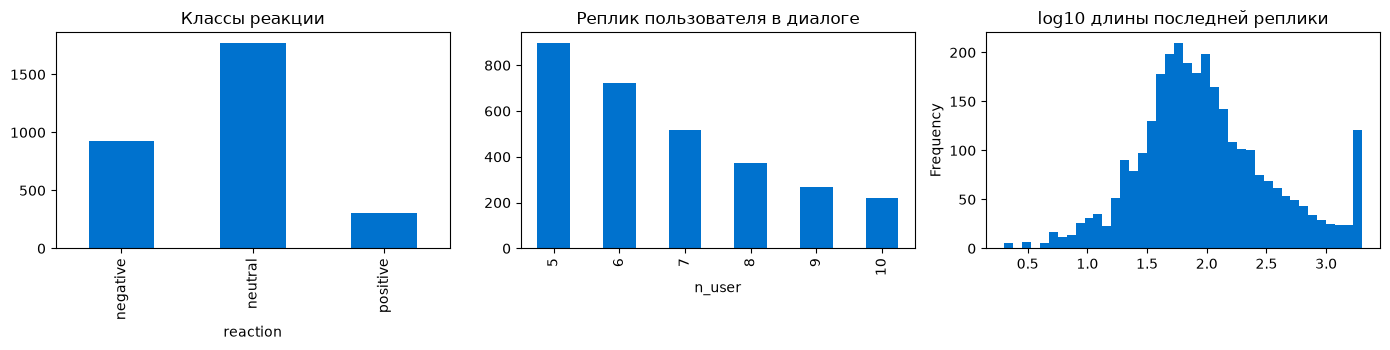

{'neutral': 0.591, 'negative': 0.308, 'positive': 0.101}


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
df.reaction.value_counts().reindex(su.REACTIONS).plot.bar(ax=axes[0], color="#0072CE", title="Классы реакции")
df.n_user.value_counts().sort_index().plot.bar(ax=axes[1], color="#0072CE", title="Реплик пользователя в диалоге")
np.log10(df.len_last + 1).plot.hist(bins=40, ax=axes[2], color="#0072CE", title="log10 длины последней реплики")
plt.tight_layout(); plt.show()
print(df.reaction.value_counts(normalize=True).round(3).to_dict())

In [ ]:
# связь реакции с простыми числовыми признаками
display(df.groupby("reaction")[["n_user", "len_last", "len_asst"]].median())
show_table(pd.crosstab(df.n_user, df.reaction, normalize="index").round(3))

,n_user,len_last,len_asst
reaction,,,
negative,6.0,81.0,1350.333333
neutral,6.0,86.0,1370.190476
positive,7.0,63.0,1098.625000


reaction,negative,neutral,positive
n_user,,,
5,0.280,0.625,0.095
6,0.320,0.598,0.082
7,0.312,0.572,0.116
8,0.344,0.554,0.102
9,0.309,0.561,0.130
10,0.305,0.577,0.118


Классы сильно несбалансированы: `neutral` около 59%, `negative` около 31%, `positive` около 10%. Поэтому accuracy тут почти бесполезна: модель, которая всегда отвечает `neutral`, получит около 0.59, не поняв ничего. Подробнее про метрики в разделе 3.

In [ ]:
# все реплики пользователя в одной таблице (одна строка — одна реплика)
turn_rows = []
for d in dialogs:
    for i, t in enumerate(d["turns"]):
        turn_rows.append({"dialog_id": d["dialog_id"], "pos": i, "role": t["role"],
                          "text": t["text"] or "", "language": d["language"]})
turns = pd.DataFrame(turn_rows)
turns["chars"] = turns.text.str.len()

# как часто встречаются служебные сочетания
user_texts = turns[turns.role == "user"].text
for name, pattern in [("настоящий \\r", "\r"), ("буквальный \\n", "\\n"), ("буквальный \\r", "\\r"),
                      ("буквальный \\t", "\\t"), ("//", "//"), ("\\\\", "\\\\")]:
    print(f"{name:16s} {user_texts.str.contains(pattern, regex=False).mean():.2%} реплик")

настоящий \r     0.00% реплик
буквальный \n    0.40% реплик
буквальный \r    0.11% реплик
буквальный \t    0.16% реплик
//               2.15% реплик
\\               0.05% реплик


## 2. Чистка и обработка текста

Смотрим, что мешает: пустые реплики, огромные вставки, шаблонные запросы и почти-дубликаты.

In [ ]:
print("пустая последняя реплика:", (df.len_last == 0).sum())
print("последняя реплика длиннее", su.MAX_CHARS, "символов:", (df.len_last >= su.MAX_CHARS).sum())
grp = df.groupby("group").agg(n=("reaction", "size"), n_labels=("reaction", "nunique"))
dup = grp[grp.n > 1]
print("групп с одинаковым началом первой реплики:", len(dup), " диалогов в них:", dup.n.sum(),
      " групп с противоречивыми метками:", (dup.n_labels > 1).sum())
for g in dup.sort_values("n", ascending=False).head(2).index:
    print(); print(df[df.group == g][["last_raw", "reaction", "last_asst", "dialog_id"]].head(3).to_string())


пустая последняя реплика: 0
последняя реплика длиннее 2000 символов: 101
групп с одинаковым началом первой реплики: 15  диалогов в них: 32  групп с противоречивыми метками: 4

                                                                                                                                                                                                                                      last_raw  reaction                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                

Решения по чистке, с причинами:

- **Длинные вставки обрезаем** до `MAX_CHARS` символов: один диалог с куском кода иначе забивает словарь тысячами редких слов (закон Ципфа из семинара 4).
- **Дубликаты не удаляем.** Это реальные запросы, и метки у них могут различаться (в примере выше одинаковое «hi» получило разные реакции). Но все диалоги с одним началом первой реплики держим по одну сторону разбиения: иначе модель «узнает» шаблон в тесте, и оценка завысится (схемы разбиения, семинар 4).
- **Текст для модели:** берём реплики пользователя, кроме первой. Первая реплика — постановка задачи, реакции в ней ещё нет. Ответы ассистента не берём: они длинные (в среднем около 1500 символов) и шумные.
- **Токенизация:** `wordpunct_tokenize`, нижний регистр, стемминг `SnowballStemmer`. **Стоп-слова не убираем**: в списке есть «not» и «no», а отрицание важно для реакции (предупреждение из семинара 4). Знаки «!» и «?» оставляем, а в `TfidfVectorizer` ставим `token_pattern=r"\S+"`, потому что стандартный шаблон их выбросил бы.

In [ ]:
example = df.loc[df.reaction == "negative"].iloc[0]
print("сырая последняя реплика:", example.last_raw[:200])
print("после обработки:        ", example.last_user[:200])

сырая последняя реплика: recalculate everything considering the porportions of each species, and everything that gets affected by that incorrect calculation
после обработки:         recalcul everyth consid the porport of each speci and everyth that get affect by that incorrect calcul


## 3. Разбиение и метрики

**Разбиение.** 20% размеченных диалогов откладываем в итоговый тестовый сет и не трогаем до раздела 8. На остальных 80% подбираем модели и параметры: внешние 5 фолдов дают честную оценку, внутри каждого `GridSearchCV` выбирает гиперпараметры (вложенная кросс-валидация, семинар 4). Схема везде `StratifiedGroupKFold`: сохраняет доли классов и держит группы дубликатов вместе.

**Метрики.** Главная — **macro-F1**: F1 каждого класса считается отдельно и усредняется без учёта размера класса, поэтому провал на редком `positive` сразу виден. Рядом: accuracy, balanced accuracy, precision и recall по классам, матрица ошибок. Ещё считаем **macro-F1 на равномерном тесте** (`macro_f1_bal`): каждому объекту вес 1 / размер его класса. По заданию на скрытом тесте распределение классов другое (у обоих dummy-моделей accuracy около 1/3, значит классов там примерно поровну), и precision зависит от долей классов.

In [ ]:
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(outer.split(df, df.reaction, df.group))
train, test = df.iloc[train_idx].reset_index(drop=True), df.iloc[test_idx].reset_index(drop=True)
print("train:", len(train), train.reaction.value_counts(normalize=True).round(3).to_dict())
print("test: ", len(test), test.reaction.value_counts(normalize=True).round(3).to_dict())
print("общих групп:", len(set(train.group) & set(test.group)))

outer_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED + 1)
inner_cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED + 2)
outer_folds = list(outer_cv.split(train, train.reaction, train.group))

train: 2400 {'neutral': 0.591, 'negative': 0.308, 'positive': 0.101}
test:  600 {'neutral': 0.592, 'negative': 0.308, 'positive': 0.1}
общих групп: 0


## 4. Baseline

Две модели без обучения на тексте: «всегда самый частый класс» и «случайно в пропорциях классов». Всё, что не обгоняет их по macro-F1, ничего не выучило.

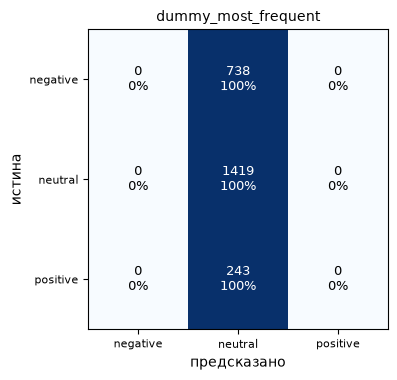

In [ ]:
MODELS = su.reaction_models(SEED)

def nested_cv(name):
    """Вложенная кросс-валидация: внутри каждого внешнего фолда GridSearchCV подбирает параметры."""
    pipe, grid = MODELS[name]
    oof = np.empty(len(train), dtype=object); chosen = []
    for fit_idx, val_idx in outer_folds:
        fit_part, val_part = train.iloc[fit_idx], train.iloc[val_idx]
        if grid:
            search = GridSearchCV(pipe, grid, cv=inner_cv, scoring="f1_macro", n_jobs=-1)
            search.fit(fit_part, fit_part.reaction, groups=fit_part.group)
            model, best = search.best_estimator_, search.best_params_
        else:
            model, best = clone(pipe).fit(fit_part, fit_part.reaction), {}
        oof[val_idx] = model.predict(val_part); chosen.append(best)
    return oof, chosen

cv_rows, cv_pred, cv_params = [], {}, {}
cv_pred["dummy_most_frequent"], cv_params["dummy_most_frequent"] = nested_cv("dummy_most_frequent")
cv_rows.append({"model": "dummy_most_frequent", **su.reaction_metrics(train.reaction, cv_pred["dummy_most_frequent"])})
COLS = ["model", "macro_f1", "macro_f1_bal", "accuracy", "balanced_acc", "R_negative", "R_neutral", "R_positive", "F1_positive"]
show_table(pd.DataFrame(cv_rows)[COLS].round(3))
su.plot_confusions(train.reaction, {"dummy_most_frequent": cv_pred["dummy_most_frequent"]})

## 5. Три базовые модели

На одном и том же признаковом пространстве (TF-IDF, униграммы и биграммы по уточняющим репликам): Naive Bayes (занятие 1), логистическая регрессия и линейный SVM (занятие 3). У двух последних `class_weight="balanced"` для борьбы с дисбалансом, у Naive Bayes `fit_prior=False`, то есть равные априорные вероятности классов. Параметры (`alpha`, `C`) подбираются внутри вложенной кросс-валидации.

In [ ]:
for name in ["nb", "logreg", "linear_svm"]:
    cv_pred[name], cv_params[name] = nested_cv(name)
    cv_rows.append({"model": name, **su.reaction_metrics(train.reaction, cv_pred[name])})
cv_table = pd.DataFrame(cv_rows)[COLS].round(3)
show_table(cv_table)

,model,macro_f1,macro_f1_bal,accuracy,balanced_acc,R_negative,R_neutral,R_positive,F1_positive
0,dummy_most_frequent,0.248,0.167,0.591,0.333,0.000,1.000,0.000,0.000
1,nb,0.443,0.376,0.652,0.456,0.527,0.825,0.016,0.031
2,logreg,0.526,0.498,0.647,0.521,0.562,0.761,0.239,0.267
3,linear_svm,0.491,0.428,0.664,0.483,0.499,0.846,0.103,0.164


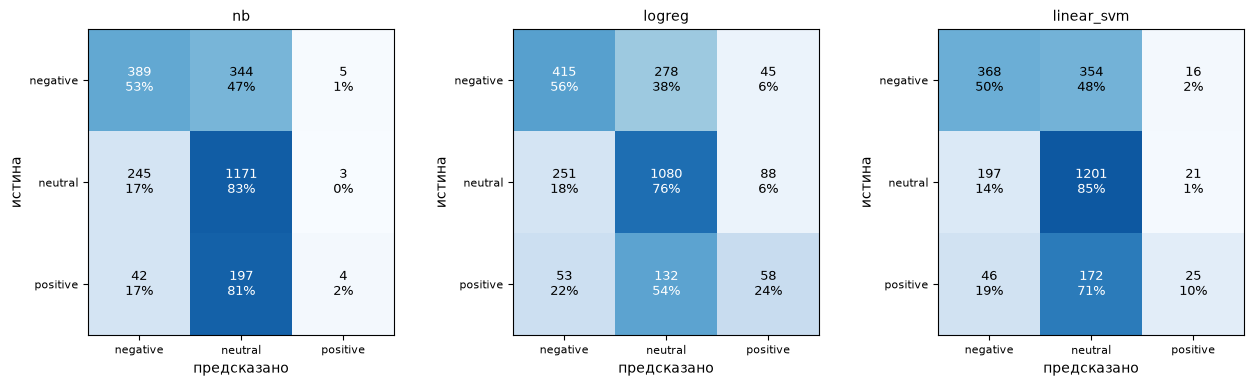

In [ ]:
su.plot_confusions(train.reaction, {n: cv_pred[n] for n in ["nb", "logreg", "linear_svm"]})

In [ ]:
# какие параметры выбирались в разных фолдах (если разнятся сильно, оценки около одинаковы)
for name in ["nb", "logreg", "linear_svm"]:
    print(name, cv_params[name])

nb [{'m__alpha': 0.1}, {'m__alpha': 0.1}, {'m__alpha': 0.1}, {'m__alpha': 0.1}, {'m__alpha': 0.1}]
logreg [{'m__C': 1}, {'m__C': 0.3}, {'m__C': 1}, {'m__C': 1}, {'m__C': 1}]
linear_svm [{'m__C': 0.3}, {'m__C': 1}, {'m__C': 0.3}, {'m__C': 0.3}, {'m__C': 0.3}]


## 6. Своя модель

Две идеи, обе из пройденного:

1. **`own_blocks_lr`**: у «всех уточнений» и «последней реплики» свои словари TF-IDF, плюс логарифмы числовых признаков (число реплик, длина последней реплики, средняя длина ответа). Идея в том, что последняя реплика — отдельный сигнал (прощание, благодарность или претензия), и в общем мешке слов он тонет.
2. **`own_svd_rbf_svm`**: TF-IDF, затем SVD до 150 компонент (семинар 5, снижение размерности для разреженных матриц), затем SVM с RBF-ядром. Эксперимент: поможет ли нелинейная граница на сжатом представлении.

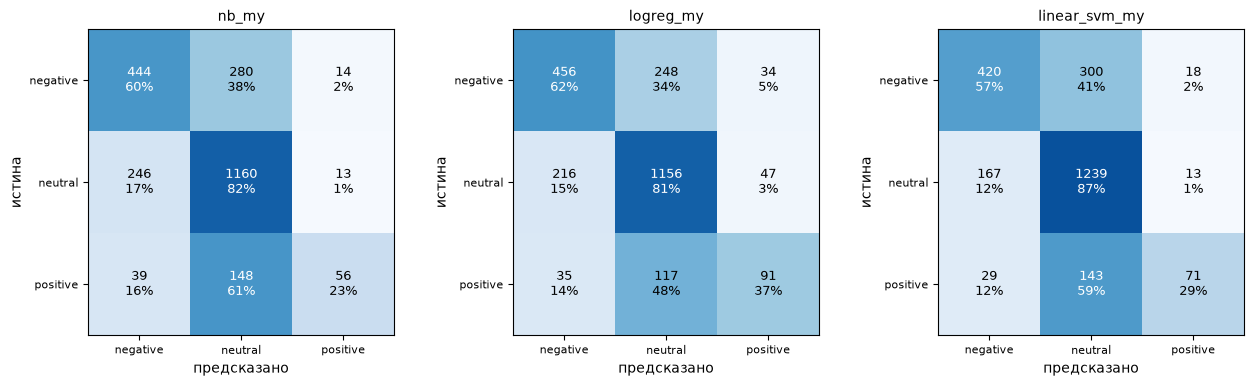

In [ ]:
for name in ["nb_my", "logreg_my", "linear_svm_my"]:
    cv_pred[name], cv_params[name] = nested_cv(name)
    cv_rows.append({"model": name, **su.reaction_metrics(train.reaction, cv_pred[name])})
cv_table = pd.DataFrame(cv_rows)[COLS].round(3)
show_table(cv_table)
su.plot_confusions(train.reaction, {n: cv_pred[n] for n in ["nb_my", "logreg_my", "linear_svm_my"]})

In [ ]:
show_table(cv_table)


,model,macro_f1,macro_f1_bal,accuracy,balanced_acc,R_negative,R_neutral,R_positive,F1_positive
0,dummy_most_frequent,0.248,0.167,0.591,0.333,0.000,1.000,0.000,0.000
1,nb,0.443,0.376,0.652,0.456,0.527,0.825,0.016,0.031
2,logreg,0.526,0.498,0.647,0.521,0.562,0.761,0.239,0.267
3,linear_svm,0.491,0.428,0.664,0.483,0.499,0.846,0.103,0.164
4,nb_my,0.573,0.524,0.692,0.550,0.602,0.817,0.230,0.344
5,logreg_my,0.619,0.593,0.710,0.602,0.618,0.815,0.374,0.439
6,linear_svm_my,0.610,0.560,0.721,0.578,0.569,0.873,0.292,0.412


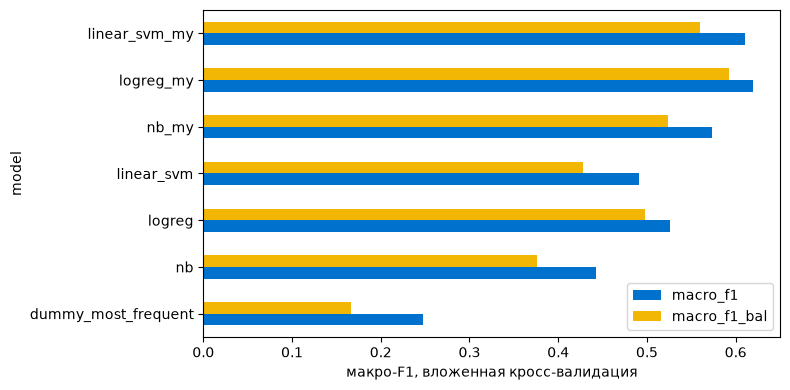

In [ ]:
cv_table.set_index("model")[["macro_f1", "macro_f1_bal"]].plot.barh(figsize=(8, 4), color=["#0072CE", "#F2B705"])
plt.xlabel("макро-F1, вложенная кросс-валидация"); plt.tight_layout(); plt.show()

## 7. Итоговая оценка на тестовом сете (один раз)

Для каждой модели `GridSearchCV` заново подбирает параметры на всём train (по группам), затем модель оценивается на отложенном тесте. Тестовый сет здесь используется впервые. Кроме метрик считаем доверительный интервал macro-F1 бутстрэпом: он покажет, какие различия между моделями вообще различимы.

In [ ]:
final, test_pred, test_rows = {}, {}, []
for name, (pipe, grid) in MODELS.items():
    if grid:
        search = GridSearchCV(pipe, grid, cv=inner_cv, scoring="f1_macro", n_jobs=-1)
        search.fit(train, train.y, groups=train.group)
        final[name] = search.best_estimator_; params = search.best_params_
    else:
        final[name] = clone(pipe).fit(train, train.y); params = {}
    test_pred[name] = final[name].predict(test)
    test_rows.append({"model": name, **su.reaction_metrics(test.y, test_pred[name]), "params": params})
test_table = pd.DataFrame(test_rows)
display(test_table[COLS].round(3))
print({r["model"]: r["params"] for r in test_rows if r["params"]})

In [ ]:
rng = np.random.default_rng(SEED)
boot = rng.integers(0, len(test), size=(500, len(test)))
rows = []
for name, pred in test_pred.items():
    vals = [su.reaction_metrics(test.y.to_numpy()[i], np.asarray(pred)[i])["macro_f1"] for i in boot]
    rows.append({"model": name, "macro_f1": np.mean(vals), "ci_low": np.percentile(vals, 2.5), "ci_high": np.percentile(vals, 97.5)})
display(pd.DataFrame(rows).round(3))

In [ ]:
pc = test_table.set_index("model")[[f"{a}_{c}" for c in su.REACTIONS for a in ("P", "R", "F1")]].round(3)
display(pc)
best = test_table.loc[~test_table.model.str.startswith("dummy")].sort_values("macro_f1").iloc[-1].model
print("лучшая по macro-F1 на тесте:", best)
display(su.confusion(test.y, test_pred[best]))

## 8. Разбор ошибок

In [ ]:
t = test.copy(); t["pred"] = test_pred[best]
def show(true, pred, n=5):
    mask = (t.y == true) & (t.pred == pred)
    print(f"\n=== истина {true}, предсказано {pred}: {mask.sum()} диалогов ===")
    for _, r in t[mask].head(n).iterrows():
        print(f"[{r.dialog_id}] {r.last_raw[:180]!r}")
show("positive", "neutral"); show("negative", "neutral"); show("neutral", "negative"); show("positive", "positive", 3)

In [ ]:
t["ok"] = t.y == t.pred
print(t.groupby("n_user").ok.mean().round(3))
print(t.groupby(pd.qcut(t.len_last, 4, duplicates="drop")).ok.mean().round(3))

**Выводы** (заполнить по настоящим числам из таблиц выше): что дала балансировка классов; какая модель победила и различимы ли модели с учётом доверительных интервалов; какой источник текста лучше (раздел 7); где модель путает `positive` и `neutral` и почему; чем отличаются оценки кросс-валидации и теста; почему своя модель помогла или не помогла.

## 9. Сохранение моделей

Сохраняем конвейеры целиком (семинар 4, раздел 9): загруженная модель принимает таблицу из `to_frame` и сама делает всё остальное. Рядом кладём версии библиотек и метрики, с которыми модель уходила в работу. Финальные модели переобучаем на всех размеченных диалогах с уже выбранными параметрами; оценки в отчёте остаются теми, что получены на отложенном тесте.

In [ ]:
meta = {"sklearn": sklearn.__version__, "python": platform.python_version(), "models": {}}
for name, (pipe, grid) in MODELS.items():
    model = clone(final[name]).fit(df, df.y)               # те же параметры, все размеченные данные
    joblib.dump(model, os.path.join(su.ARTIFACTS, f"reaction_{name}.joblib"))
    row = test_table[test_table.model == name].iloc[0]
    meta["models"][name] = {"macro_f1_test": round(float(row.macro_f1), 4), "params": {k: str(v) for k, v in row.params.items()}}
with open(os.path.join(su.ARTIFACTS, "reaction_meta.json"), "w", encoding="utf-8") as f:
    json.dump(meta, f, ensure_ascii=False, indent=1)
print(sorted(os.listdir(su.ARTIFACTS)))
# проверка: загрузка даёт те же предсказания
loaded = su.init_reaction_models()
ok = all((loaded[n].predict(test) == clone(final[n]).fit(df, df.y).predict(test)).all() for n in ["logreg"])
print("загруженная модель совпадает с обученной:", ok)